# 03 – RFM segmentation & cohort retention

**RFM** gives each customer three scores: **Recency** (how recently they bought), **Frequency** (how many orders),
**Monetary** (how much they spent). A **cohort** = all customers whose first order was in the same month.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sqlalchemy import text
from db import get_engine

engine = get_engine("olist")
orders = pd.read_sql(text("""
    SELECT customer_unique_id, order_id, MIN(purchase_time) AS purchase_time,
           SUM(price) AS order_value
    FROM sales GROUP BY customer_unique_id, order_id"""), engine)
orders["purchase_time"] = pd.to_datetime(orders["purchase_time"])
print(f"{len(orders):,} delivered orders from {orders.customer_unique_id.nunique():,} customers")

96,478 delivered orders from 93,358 customers


In [2]:
snapshot = orders["purchase_time"].max() + pd.Timedelta(days=1)
rfm = orders.groupby("customer_unique_id").agg(
    recency=("purchase_time", lambda x: (snapshot - x.max()).days),
    frequency=("order_id", "nunique"),
    monetary=("order_value", "sum"))

# R and M: 1-5 scores by quintile (5 = best)
rfm["R"] = pd.qcut(rfm["recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["M"] = pd.qcut(rfm["monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)
# F: most customers bought only once, so quintiles do not work. Use simple groups.
rfm["F"] = rfm["frequency"].map(lambda n: 1 if n == 1 else (3 if n == 2 else 5))
print(rfm["frequency"].value_counts().sort_index().head(8))

def segment(r):
    if r.F >= 3 and r.R >= 3: return "Loyal"
    if r.F >= 3:              return "Loyal but slipping"
    if r.R >= 4 and r.M >= 4: return "New high-value"
    if r.R >= 4:              return "New"
    if r.M >= 4:              return "Lost high-value"
    return "Lost / one-time"

rfm["segment"] = rfm.apply(segment, axis=1)

summary = rfm.groupby("segment").agg(customers=("monetary", "size"),
                                     revenue=("monetary", "sum"),
                                     avg_spend=("monetary", "mean"))
summary["pct_customers"] = (100 * summary.customers / summary.customers.sum()).round(1)
summary["pct_revenue"] = (100 * summary.revenue / summary.revenue.sum()).round(1)
summary = summary.sort_values("revenue", ascending=False).round(1)
summary

frequency
1    90557
2     2573
3      181
4       28
5        9
6        5
7        3
9        1
Name: count, dtype: int64


,customers,revenue,avg_spend,pct_customers,pct_revenue
segment,,,,,
Lost high-value,20546,5522306.6,268.8,22.0,41.8
New high-value,14452,3870315.2,267.8,15.5,29.3
Lost / one-time,33787,1887817.4,55.9,36.2,14.3
New,21772,1212650.1,55.7,23.3,9.2
Loyal,1813,484852.5,267.4,1.9,3.7
Loyal but slipping,988,243556.3,246.5,1.1,1.8


In [3]:
rfm.reset_index().to_csv("../data/rfm_segments.csv", index=False)

# Headline number: what share of revenue comes from the top 10% / 20% of customers?
m = rfm["monetary"].sort_values(ascending=False).reset_index(drop=True)
for top in (0.01, 0.10, 0.20):
    n = int(len(m) * top)
    print(f"Top {top:.0%} of customers ({n:,}) bring {m.iloc[:n].sum() / m.sum():.1%} of revenue")
print(f"Average spend: top 10% = R$ {m.iloc[:int(len(m)*0.1)].mean():.0f} vs. rest = R$ {m.iloc[int(len(m)*0.1):].mean():.0f}")

Top 1% of customers (933) bring 11.5% of revenue
Top 10% of customers (9,335) bring 41.1% of revenue
Top 20% of customers (18,671) bring 56.6% of revenue
Average spend: top 10% = R$ 582 vs. rest = R$ 93


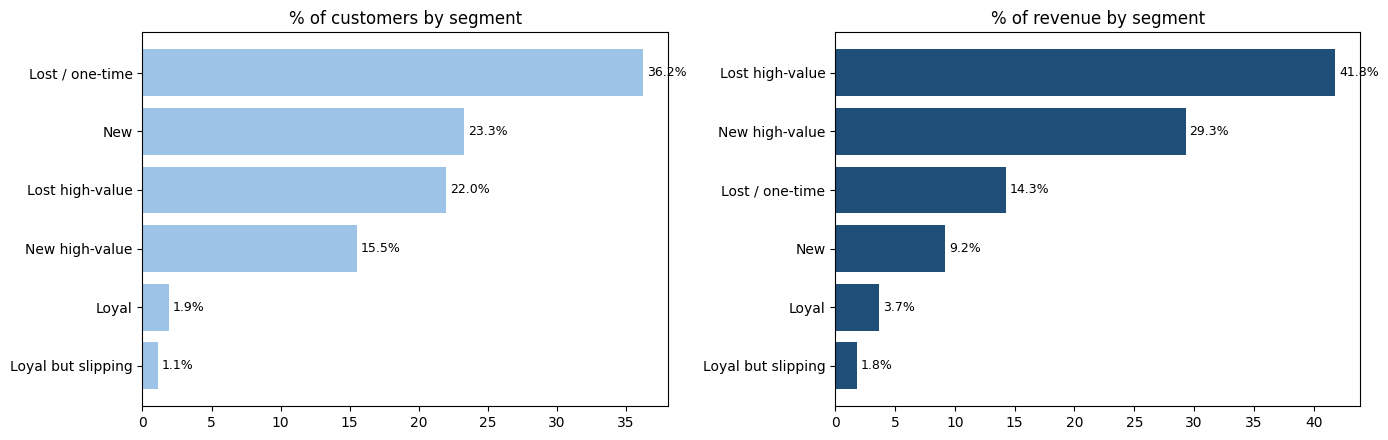

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col, color, title in [(axes[0], "pct_customers", "#9dc3e6", "% of customers by segment"),
                              (axes[1], "pct_revenue", "#1f4e79", "% of revenue by segment")]:
    s = summary.sort_values(col)
    ax.barh(s.index, s[col], color=color); ax.set_title(title)
    for i, v in enumerate(s[col]):
        ax.text(v + 0.3, i, f"{v}%", va="center", fontsize=9)
plt.tight_layout()
plt.savefig("../dashboard/rfm_segments.png", dpi=150, bbox_inches="tight")
plt.show()

## Cohort retention

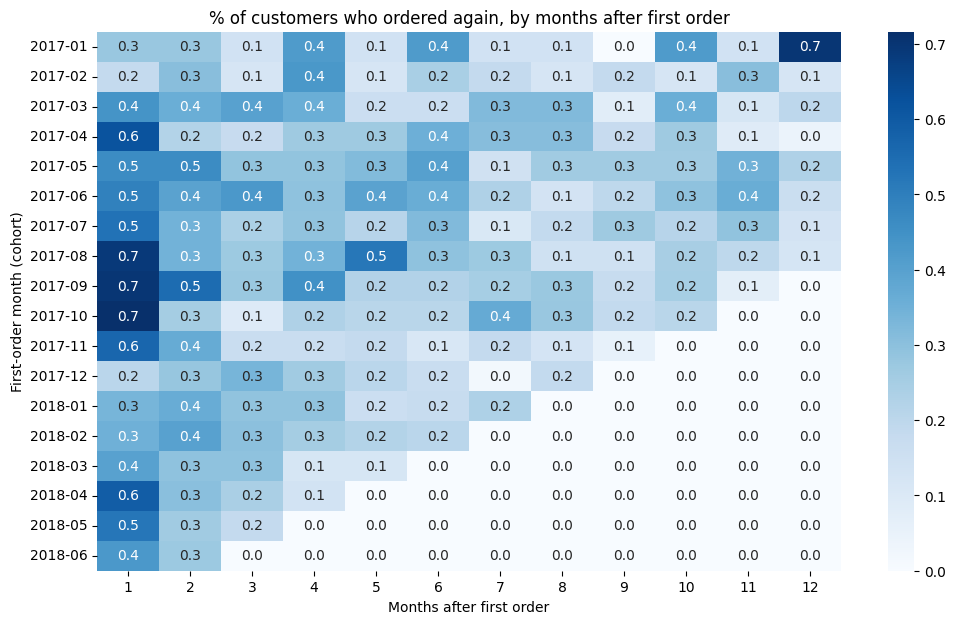

Average month-1 retention: 0.47%
Average retention over months 1-12: 0.20%


In [5]:
orders["order_month"] = orders["purchase_time"].dt.to_period("M")
orders["cohort"] = orders.groupby("customer_unique_id")["order_month"].transform("min")
orders["months_since"] = (orders["order_month"] - orders["cohort"]).apply(lambda d: d.n)

counts = (orders.groupby(["cohort", "months_since"])["customer_unique_id"]
                .nunique().unstack(fill_value=0))
retention = counts.div(counts[0], axis=0) * 100
retention = retention.loc["2017-01":"2018-06", 1:12]   # keep cohorts with enough data

plt.figure(figsize=(12, 7))
sns.heatmap(retention, annot=True, fmt=".1f", cmap="Blues")
plt.title("% of customers who ordered again, by months after first order")
plt.xlabel("Months after first order"); plt.ylabel("First-order month (cohort)")
plt.savefig("../dashboard/cohort_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Average month-1 retention: {retention[1].mean():.2f}%")
print(f"Average retention over months 1-12: {retention.stack().mean():.2f}%")

# long format for the Power BI matrix
cohort_long = retention.stack().rename("retention_pct").reset_index()
cohort_long.columns = ["cohort", "months_since", "retention_pct"]
cohort_long["cohort"] = cohort_long["cohort"].astype(str)
cohort_long["retention_pct"] = cohort_long["retention_pct"].round(2)
cohort_long.to_csv("../data/cohort_retention.csv", index=False)

## Findings

- **97% of customers bought only once** (90,557 of 93,358), so frequency is scored in simple groups instead of quintiles.
- **Revenue is concentrated:** the **top 10% of customers bring 41.1% of revenue** and the top 20% bring **56.6%**. A top-10% customer spends R$ 582 on average vs R$ 93 for everyone else.
- **Lost high-value** customers (big spenders who haven't bought recently) are 22.0% of customers but **41.8% of revenue** – the most valuable group to win back.
- **New high-value** customers (15.5% of customers, 29.3% of revenue) are the group to turn into repeat buyers *now*.
- **Loyal** customers (2+ orders, recent) are only **1.9%** of customers.
- **Cohort retention is very low:** on average only **0.47%** of a cohort orders again in the month after their first order, and about 0.2% in any later month.

**Possible reasons:** many purchases are one-off or durable items (furniture, bed/bath, watches, electronics); Olist is a marketplace, so customers may not remember *which* store they bought from; there is no loyalty programme; and late deliveries (2.57★) push customers away.

**Suggestion:** a win-back campaign for the *Lost high-value* segment (e.g. a personalised voucher for the category they bought before) and a second-order incentive sent 2–4 weeks after delivery for *New high-value* customers. Fixing late deliveries in the north/north-east would also protect review scores.